# Balanced + Feature-Augmented CICIoT2023 — LSTM, Five-Seed Evaluation

## 1. Environment and reproducibility

In [1]:
import json
import platform
import joblib
import sklearn
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)

Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time
import json
from pathlib import Path


## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.

### Directly clean Augmented data 

In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())

Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [4]:
# ============================================================
# Dataset validation + feature-ablation configuration
# ============================================================

# Name of the target column used throughout the notebook.
LABEL_COLUMN = "label"

# ------------------------------------------------------------
# Anomaly-score features used by the FA configuration
# ------------------------------------------------------------
ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# ============================================================
# Select the ablation configuration
# ============================================================

# Change ONLY this line when running a different ablation.
#
# Available configurations:
#
# "Full_FA"
#     Original traffic features
#     + IF_Anomaly_Score
#     + AE_Anomaly_Score
#     + SUOD_Anomaly_Score
#
# "No_FA"
#     Original traffic features only.
#     All three anomaly-score features are removed.
#
# "IF_only"
#     Original traffic features
#     + IF_Anomaly_Score
#
# "AE_only"
#     Original traffic features
#     + AE_Anomaly_Score
#
# "SUOD_only"
#     Original traffic features
#     + SUOD_Anomaly_Score

ABLATION_MODE = "No_FA"

# ============================================================
# Validate the originally loaded augmented datasets
# ============================================================

# The same augmented train, validation, and test partitions are
# used for every ablation configuration. Only the selected
# anomaly-score columns are removed.
#
# This preserves:
# - identical samples,
# - identical labels,
# - identical split membership,
# - identical downstream preprocessing,
# - identical LSTM architecture,
# - identical optimized hyperparameters,
# - identical five random seeds.

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    # Confirm that the target label exists.
    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    # Confirm that the originally loaded augmented datasets
    # contain all three anomaly-score features.
    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )

# ============================================================
# Determine which anomaly-score features should be removed
# ============================================================

if ABLATION_MODE == "Full_FA":

    # Keep all three anomaly-score features.
    features_to_drop = []

elif ABLATION_MODE == "No_FA":

    # Remove all anomaly-score features.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":

    # Keep only the Isolation Forest anomaly score.
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":

    # Keep only the Autoencoder reconstruction score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":

    # Keep only the SUOD ensemble anomaly score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:

    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use one of: Full_FA, No_FA, IF_only, "
        "AE_only, or SUOD_only."
    )

# ============================================================
# Apply the selected ablation
# ============================================================

# Only the selected anomaly-score columns are removed.
# No samples or labels are changed.

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()

# ============================================================
# Rebuild the feature list after ablation
# ============================================================

# This step is important because the original feature_columns
# list was created before the anomaly-score features were
# removed.

feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

# ============================================================
# Validate feature consistency across all partitions
# ============================================================

validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

# The feature order must remain identical because the same
# preprocessing and model pipeline is used afterward.

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns do not match "
        "after applying the ablation configuration."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns do not match "
        "after applying the ablation configuration."
    )

# ============================================================
# Confirm which anomaly-score features remain
# ============================================================

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

# ============================================================
# Print experiment summary
# ============================================================

print("=" * 60)
print("Feature-ablation configuration")
print("=" * 60)

print(
    f"Ablation mode: "
    f"{ABLATION_MODE}"
)

print(
    f"Number of input features: "
    f"{len(feature_columns)}"
)

print(
    f"Kept anomaly-score features: "
    f"{kept_anomaly_features}"
)

print(
    f"Dropped anomaly-score features: "
    f"{features_to_drop}"
)

print(
    f"Training instances: "
    f"{len(train_data):,}"
)

print(
    f"Validation instances: "
    f"{len(validation_data):,}"
)

print(
    f"Test instances: "
    f"{len(test_data):,}"
)

print("=" * 60)


Feature-ablation configuration
Ablation mode: No_FA
Number of input features: 32
Kept anomaly-score features: []
Dropped anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246


### Separate augmented features and multiclass labels

In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())

Training features:   (354737, 32)
Validation features: (118246, 32)
Test features:       (118246, 32)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels

In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)

Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Resample only the training set, then standardize the features

In [7]:
# Run once if imbalanced-learn is not installed:
# !pip install imbalanced-learn

from collections import Counter
from imblearn.over_sampling import SMOTE


# ============================================================
# Define the desired total number of training instances
# for the selected encoded classes after SMOTE
# ============================================================
target_class_counts = {
    0: 8248 + 1752,
    1: 100 + 9900,
    5: 2736 + 7264,
    6: 3729 + 6271,
    7: 188 + 9812,
}


# Validate the strategy against the encoded training labels.
training_distribution_before_smote = Counter(
    map(int, y_train)
)

unknown_target_codes = (
    set(target_class_counts)
    - set(training_distribution_before_smote)
)

if unknown_target_codes:
    raise ValueError(
        "SMOTE target codes are absent from the training set: "
        f"{sorted(unknown_target_codes)}"
    )

invalid_target_counts = {
    class_code: target_count
    for class_code, target_count in target_class_counts.items()
    if target_count < training_distribution_before_smote[class_code]
}

if invalid_target_counts:
    raise ValueError(
        "Each SMOTE target must be at least its original training "
        "count. Invalid targets: "
        f"{invalid_target_counts}"
    )


# ============================================================
# Fit and apply SMOTE to unstandardized training data only
# ============================================================
smote = SMOTE(
    sampling_strategy=target_class_counts,
    random_state=SEED,
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train,
)

X_train_resampled = np.asarray(
    X_train_resampled, dtype=np.float32
)
y_train_resampled = np.asarray(
    y_train_resampled, dtype=y_train.dtype
)


# Validation and test data are not used by SMOTE.
print(
    "Original training class distribution: "
    f"{training_distribution_before_smote}"
)
print(
    "Resampled training class distribution: "
    f"{Counter(map(int, y_train_resampled))}"
)
print(f"Resampled training features: {X_train_resampled.shape}")
print(f"Unchanged validation features: {X_val.shape}")
print(f"Unchanged test features: {X_test.shape}")

Original training class distribution: Counter({2: 258100, 3: 61405, 4: 20231, 0: 8248, 6: 3729, 5: 2736, 7: 188, 1: 100})
Resampled training class distribution: Counter({2: 258100, 3: 61405, 4: 20231, 6: 10000, 0: 10000, 5: 10000, 7: 10000, 1: 10000})
Resampled training features: (389736, 32)
Unchanged validation features: (118246, 32)
Unchanged test features: (118246, 32)


In [8]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on the resampled training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train_resampled
).astype(np.float32)


# Apply the same fitted scaler without refitting.
# Validation and test instances retain their original distributions.
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data and aligned training labels
# ============================================================
if len(X_train_scaled) != len(y_train_resampled):
    raise ValueError(
        "Scaled training features and resampled labels are misaligned."
    )

for dataset_name, feature_data in {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Test": X_test_scaled,
}.items():
    if not np.isfinite(feature_data).all():
        raise ValueError(
            f"Scaled {dataset_name.lower()} features contain "
            "invalid values."
        )


print(f"Scaled resampled training features: {X_train_scaled.shape}")
print(f"Scaled validation features:         {X_val_scaled.shape}")
print(f"Scaled test features:               {X_test_scaled.shape}")
print(
    f"\nResampled training mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)
print(
    f"Resampled training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)

Scaled resampled training features: (389736, 32)
Scaled validation features:         (118246, 32)
Scaled test features:               (118246, 32)

Resampled training mean after scaling: 0.000000
Resampled training standard deviation after scaling: 1.000000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## 3. LSTM input representation and optimization control


In [9]:
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Preserve the original one-time-step representation.
input_attribute_count = (
    X_train_scaled.shape[1]
)

X_train_reshaped_lstm = (
    X_train_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)

X_val_reshaped_lstm = (
    X_val_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)

X_test_reshaped_lstm = (
    X_test_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)

print(
    "LSTM training shape:",
    X_train_reshaped_lstm.shape,
)
print(
    "LSTM validation shape:",
    X_val_reshaped_lstm.shape,
)
print(
    "LSTM test shape:",
    X_test_reshaped_lstm.shape,
)


LSTM training shape: (389736, 1, 32)
LSTM validation shape: (118246, 1, 32)
LSTM test shape: (118246, 1, 32)


In [10]:
RUN_OPTUNA = False
N_OPTUNA_TRIALS = 25

MAX_EPOCHS_LSTM = 100
EARLY_STOPPING_PATIENCE = 10

PRESTORED_LSTM_PARAMS_FILE = Path(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_lstm_CICI_Balanced.json"
)

OPTUNA_LSTM_OUTPUT_FILE = (
    Path.cwd()
    / "best_params_lstm_CICI_Balanced.json"
)

print(
    f"RUN_OPTUNA = {RUN_OPTUNA}"
)


RUN_OPTUNA = False


In [11]:
class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )
        self.number_of_classes = int(
            number_of_classes
        )
        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32,
        )
        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None
        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )
        return config


def objective_lstm(trial):
    """Train one LSTM trial and return validation macro F1."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    hidden_layer1_lstm = trial.suggest_int(
        "hidden_layer1_lstm",
        32,
        128,
        step=16,
    )

    hidden_layer2_lstm = trial.suggest_int(
        "hidden_layer2_lstm",
        16,
        64,
        step=16,
    )

    dropout_rate_lstm = trial.suggest_float(
        "dropout_rate_lstm",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg_lstm = trial.suggest_float(
        "l2_reg_lstm",
        1e-06,
        0.001,
        log=True,
    )

    batch_size_lstm = trial.suggest_categorical(
        "batch_size_lstm",
        [64, 128, 256],
    )

    learning_rate_lstm = trial.suggest_float(
        "learning_rate_lstm",
        1e-05,
        0.01,
        log=True,
    )

    model_lstm_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),
            LSTM(
                hidden_layer1_lstm,
                return_sequences=True,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
            Dropout(
                dropout_rate_lstm
            ),
            LSTM(
                hidden_layer2_lstm,
                return_sequences=False,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
            Dropout(
                dropout_rate_lstm
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
        ],
        name="LSTM_Optuna_Trial",
    )

    model_lstm_trial.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=(
                learning_rate_lstm
            )
        ),
        metrics=[
            "accuracy",
            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    model_lstm_trial.fit(
        X_train_reshaped_lstm,
        y_train_resampled,
        epochs=MAX_EPOCHS_LSTM,
        batch_size=batch_size_lstm,
        validation_data=(
            X_val_reshaped_lstm,
            y_val,
        ),
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),
            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            )
        ],
        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_lstm_trial.predict(
            X_val_reshaped_lstm,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=np.arange(
            number_of_classes
        ),
        average="macro",
        zero_division=0,
    )

    del model_lstm_trial
    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [13]:
# !pip install optuna-integration[keras]

In [14]:
if RUN_OPTUNA:
    import optuna
    from optuna.trial import TrialState

    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    study_lstm = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_lstm.optimize(
        objective_lstm,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )
    pruned_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )
    failed_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print("LSTM study statistics:")
    print(
        "  Finished:",
        len(study_lstm.trials),
    )
    print(
        "  Complete:",
        len(complete_trials_lstm),
    )
    print(
        "  Pruned:",
        len(pruned_trials_lstm),
    )
    print(
        "  Failed:",
        len(failed_trials_lstm),
    )
    print(
        "  Best validation macro F1:",
        f"{study_lstm.best_value:.6f}",
    )
    print(
        "  Best parameters:",
        study_lstm.best_params,
    )

    best_params_lstm_CICI_Balanced = (
        study_lstm.best_params
    )

    with open(
        OPTUNA_LSTM_OUTPUT_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_lstm_CICI_Balanced,
            json_file,
            indent=2,
        )

    print(
        "New optimized LSTM parameters saved to:",
        OPTUNA_LSTM_OUTPUT_FILE,
    )

else:
    if not PRESTORED_LSTM_PARAMS_FILE.exists():
        raise FileNotFoundError(
            "Stored LSTM parameter file was not found: "
            f"{PRESTORED_LSTM_PARAMS_FILE}"
        )

    with open(
        PRESTORED_LSTM_PARAMS_FILE,
        "r",
        encoding="utf-8",
    ) as json_file:
        best_params_lstm_CICI_Balanced = json.load(
            json_file
        )

    # Support legacy key if present.
    if (
        "l2_reg_lstm"
        not in best_params_lstm_CICI_Balanced
        and "l2_reg"
        in best_params_lstm_CICI_Balanced
    ):
        best_params_lstm_CICI_Balanced[
            "l2_reg_lstm"
        ] = best_params_lstm_CICI_Balanced.pop(
            "l2_reg"
        )

    required_lstm_parameters = {
        "hidden_layer1_lstm",
        "hidden_layer2_lstm",
        "dropout_rate_lstm",
        "l2_reg_lstm",
        "batch_size_lstm",
        "learning_rate_lstm",
    }

    missing_lstm_parameters = (
        required_lstm_parameters
        - set(
            best_params_lstm_CICI_Balanced
        )
    )

    if missing_lstm_parameters:
        raise KeyError(
            "Missing LSTM hyperparameters: "
            f"{sorted(missing_lstm_parameters)}"
        )

    print(
        "Stored LSTM hyperparameters "
        "loaded and validated."
    )

best_params_lstm_CICI_Balanced


Stored LSTM hyperparameters loaded and validated.


{'hidden_layer1_lstm': 128,
 'hidden_layer2_lstm': 32,
 'dropout_rate_lstm': 0.2,
 'l2_reg_lstm': 1.2121988223532824e-06,
 'batch_size_lstm': 64,
 'learning_rate_lstm': 0.0008338657368912076}

## 4. Final LSTM model and 5-seed evaluation


In [15]:
from pathlib import Path
import gc

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Five-run protocol
# ============================================================
RUN_SEEDS = [
    42, 43, 44, 45, 46,
]

N_FINAL_RUNS = len(
    RUN_SEEDS
)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 5


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states."""
    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


try:
    tf.config.experimental.enable_op_determinism()
    print(
        "TensorFlow deterministic operations enabled."
    )
except (
    AttributeError,
    RuntimeError,
):
    print(
        "TensorFlow deterministic-operation control "
        "is unavailable in this environment."
    )


def benchmark_full_test_prediction(
    model,
    X_input,
):
    """Measure full-test inference using one fixed protocol."""
    warmup_size = min(
        1024,
        len(X_input),
    )

    for _ in range(
        N_WARMUP_RUNS
    ):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(
        N_BENCHMARK_RUNS
    ):
        start_time = (
            time.perf_counter()
        )

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter()
            - start_time
        )

    mean_inference_time = float(
        np.mean(
            measured_times
        )
    )

    return probabilities, {
        "Inference_Time_s":
            mean_inference_time,
        "Latency_ms_per_sample":
            (
                mean_inference_time
                / len(X_input)
                * 1000.0
            ),
        "Throughput_samples_per_s":
            (
                len(X_input)
                / mean_inference_time
            ),
    }, measured_times


def calculate_fpr_metrics(
    y_true,
    y_pred,
    labels,
):
    """
    Return macro, micro/overall, weighted, and per-class FPR,
    together with one-vs-rest confusion matrices.
    """
    matrices = (
        multilabel_confusion_matrix(
            y_true,
            y_pred,
            labels=labels,
        )
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        (
            true_negative,
            false_positive,
            _,
            _,
        ) = matrix.ravel()

        denominator = (
            false_positive
            + true_negative
        )

        per_class_fpr.append(
            (
                false_positive
                / denominator
            )
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    fpr_summary = {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            (
                false_positives.sum()
                / micro_denominator
            )
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }

    return (
        fpr_summary,
        per_class_fpr,
        matrices,
    )


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate all scalar test metrics for one seed."""
    metrics = {
        "Accuracy":
            accuracy_score(
                y_true,
                y_pred,
            ),
        "Precision_macro":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "Recall_macro":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "F1_macro":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "Precision_weighted":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "Recall_weighted":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "F1_weighted":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "MCC":
            matthews_corrcoef(
                y_true,
                y_pred,
            ),
    }

    try:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = np.nan
        print(
            "Macro ROC-AUC could not be calculated: "
            f"{error}"
        )

    (
        fpr_summary,
        per_class_fpr,
        class_matrices,
    ) = calculate_fpr_metrics(
        y_true,
        y_pred,
        labels,
    )

    metrics.update(
        fpr_summary
    )

    return (
        metrics,
        per_class_fpr,
        class_matrices,
    )


def format_mean_sd(
    mean_value,
    sd_value,
):
    """Format mean ± sample SD."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return (
            f"{mean_value:.6f} ± NA"
        )

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as CSV, PDF, and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(
            number_of_classes
        ),
    )

    matrix_df = pd.DataFrame(
        matrix,
        index=label_encoder.classes_,
        columns=label_encoder.classes_,
    )
    matrix_df.index.name = "True_Label"
    matrix_df.columns.name = "Predicted_Label"

    matrix_df.to_csv(
        f"{output_stem}.csv"
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=(
            label_encoder.classes_
        ),
        yticklabels=(
            label_encoder.classes_
        ),
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.close()


# Recreate the LSTM input tensors here as a safeguard so
# the final section does not depend on execution of an earlier cell.
input_attribute_count = (
    X_train_scaled.shape[1]
)

X_train_reshaped_lstm = (
    X_train_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)

X_val_reshaped_lstm = (
    X_val_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)

X_test_reshaped_lstm = (
    X_test_scaled.reshape(
        -1,
        1,
        input_attribute_count,
    )
)


REPORT_OUTPUT_DIRECTORY = (
    Path.cwd()
    / "Balanced_FA_CICIoT2023_LSTM_5_seed_V3"
)

MODEL_OUTPUT_DIRECTORY = (
    REPORT_OUTPUT_DIRECTORY
)

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def build_final_lstm(
    parameters
):
    model = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),
            LSTM(
                parameters[
                    "hidden_layer1_lstm"
                ],
                return_sequences=True,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            LSTM(
                parameters[
                    "hidden_layer2_lstm"
                ],
                return_sequences=False,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
        ],
        name="LSTM",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=(
                parameters[
                    "learning_rate_lstm"
                ]
            )
        ),
        metrics=["accuracy"],
    )

    return model


# ============================================================
# Reproducibility artifacts for offline inference
# ============================================================
joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY / "classifier_scaler.joblib",
)

with open(
    REPORT_OUTPUT_DIRECTORY / "feature_columns.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        list(feature_columns),
        f,
        indent=2,
    )

with open(
    REPORT_OUTPUT_DIRECTORY / "class_names.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        label_encoder.classes_.tolist(),
        f,
        indent=2,
    )

np.save(
    REPORT_OUTPUT_DIRECTORY / "X_test_model_input.npy",
    X_test_reshaped_lstm,
)

np.save(
    REPORT_OUTPUT_DIRECTORY / "y_test.npy",
    np.asarray(y_test),
)

with open(
    REPORT_OUTPUT_DIRECTORY / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        best_params_lstm_CICI_Balanced,
        f,
        indent=2,
    )

environment_metadata = {
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "machine": platform.machine(),
    "tensorflow_devices": [
        {
            "name": device.name,
            "device_type": device.device_type,
        }
        for device in tf.config.list_physical_devices()
    ],
    "timing_protocol": {
        "warmup_runs": N_WARMUP_RUNS,
        "timed_full_test_repetitions_per_model": N_BENCHMARK_RUNS,
        "timer": "time.perf_counter",
        "model_loading_included": False,
        "preprocessing_included": False,
        "latency_definition": (
            "average per-sample latency derived from full-test batch inference"
        ),
    },
}

with open(
    REPORT_OUTPUT_DIRECTORY / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        environment_metadata,
        f,
        indent=2,
    )


TensorFlow deterministic operations enabled.


2026-09-27 11:02:42.582214: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [16]:
labels = np.arange(
    number_of_classes
)

run_rows = []
per_class_rows = []
representative_candidates = []

for (
    run_number,
    seed,
) in enumerate(
    RUN_SEEDS,
    start=1,
):
    print(
        "\n" + "=" * 72
    )
    print(
        f"LSTM: final run "
        f"{run_number}/{N_FINAL_RUNS}; "
        f"seed={seed}"
    )
    print(
        "=" * 72
    )

    seed_output_directory = (
        REPORT_OUTPUT_DIRECTORY
        / f"LSTM_Seed_{run_number}"
    )
    seed_output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    tf.keras.backend.clear_session()
    set_final_run_seed(
        seed
    )

    model = build_final_lstm(
        best_params_lstm_CICI_Balanced
    )

    # --------------------------------------------------------
    # Training on the SMOTE-resampled training labels.
    # --------------------------------------------------------
    training_start = (
        time.perf_counter()
    )


    history = model.fit(
        X_train_reshaped_lstm,
        y_train_resampled,
    
        epochs=MAX_EPOCHS_LSTM,
    
        batch_size=best_params_lstm_CICI_Balanced[
            "batch_size_lstm"
        ],
    
        validation_data=(
            X_val_reshaped_lstm,
            y_val,
        ),
    
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            )
        ],
    
        shuffle=True,
        verbose=1,
    )

    training_time = (
        time.perf_counter()
        - training_start
    )

    # --------------------------------------------------------
    # Validation macro F1.
    # --------------------------------------------------------
    validation_probabilities = (
        model.predict(
            X_val_reshaped_lstm,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=labels,
        average="macro",
        zero_division=0,
    )

    # --------------------------------------------------------
    # Test evaluation and inference timing.
    # --------------------------------------------------------
    evaluation = model.evaluate(
        X_test_reshaped_lstm,
        y_test,
        verbose=0,
        return_dict=True,
    )

    (
        test_probabilities,
        timing_metrics,
        timing_repetitions,
    ) = benchmark_full_test_prediction(
        model,
        X_test_reshaped_lstm,
    )

    timing_repetitions_df = pd.DataFrame(
        {
            "Repetition": np.arange(
                1,
                len(timing_repetitions) + 1,
            ),
    
            "Inference_Time_s":
                timing_repetitions,
    
            "Latency_ms_per_sample": [
                inference_time
                / len(X_test_reshaped_lstm)
                * 1000.0
                for inference_time
                in timing_repetitions
            ],
        }
    )
    
    timing_repetitions_df.to_csv(
        seed_output_directory
        / "inference_timing_repetitions.csv",
        index=False,
    )



    test_predictions = np.argmax(
        test_probabilities,
        axis=1,
    )

    (
        test_metrics,
        per_class_fpr,
        class_matrices,
    ) = calculate_test_metrics(
        y_test,
        test_predictions,
        test_probabilities,
        labels,
    )

    run_row = {
        "Model": "LSTM",
        "Run": int(run_number),
        "Seed": int(seed),
        "Training_Time_s": float(
            training_time
        ),
        "Validation_F1_macro": float(
            validation_macro_f1
        ),
        "Test_Loss": float(
            evaluation["loss"]
        ),
        **test_metrics,
        **timing_metrics,
    }

    run_rows.append(
        run_row
    )

    pd.DataFrame(
        [run_row]
    ).to_csv(
        seed_output_directory
        / "scalar_metrics.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Readable macro-only metrics.
    # --------------------------------------------------------
    macro_metrics_row = {
        "Model": run_row["Model"],
        "Run": run_row["Run"],
        "Seed": run_row["Seed"],
        "Precision_macro": run_row["Precision_macro"],
        "Recall_macro": run_row["Recall_macro"],
        "F1_macro": run_row["F1_macro"],
        "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
        "FPR_macro": run_row["FPR_macro"],
    }

    pd.DataFrame(
        [macro_metrics_row]
    ).to_csv(
        seed_output_directory
        / "macro_metrics.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Readable weighted-average metrics.
    # --------------------------------------------------------
    weighted_metrics_row = {
        "Model": run_row["Model"],
        "Run": run_row["Run"],
        "Seed": run_row["Seed"],
        "Precision_weighted": run_row["Precision_weighted"],
        "Recall_weighted": run_row["Recall_weighted"],
        "F1_weighted": run_row["F1_weighted"],
        "FPR_weighted": run_row["FPR_weighted"],
    }

    pd.DataFrame(
        [weighted_metrics_row]
    ).to_csv(
        seed_output_directory
        / "weighted_average_metrics.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Classification report.
    # --------------------------------------------------------
    seed_classification_report = (
        classification_report(
            y_test,
            test_predictions,
            labels=labels,
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        seed_classification_report
    ).transpose().to_csv(
        seed_output_directory
        / "classification_report.csv"
    )

    # --------------------------------------------------------
    # Per-class metrics + per-class FPR and TP/TN/FP/FN.
    # --------------------------------------------------------
    (
        precision_values,
        recall_values,
        f1_values,
        support_values,
    ) = precision_recall_fscore_support(
        y_test,
        test_predictions,
        labels=labels,
        zero_division=0,
    )

    seed_per_class_rows = []

    for (
        class_index,
        class_name,
    ) in enumerate(
        label_encoder.classes_
    ):
        (
            true_negative,
            false_positive,
            false_negative,
            true_positive,
        ) = class_matrices[
            class_index
        ].ravel()

        class_row = {
            "Model": "LSTM",
            "Run": int(run_number),
            "Seed": int(seed),
            "Class": class_name,
            "Precision": float(
                precision_values[
                    class_index
                ]
            ),
            "Recall": float(
                recall_values[
                    class_index
                ]
            ),
            "F1": float(
                f1_values[
                    class_index
                ]
            ),
            "FPR": float(
                per_class_fpr[
                    class_index
                ]
            ),
            "TP": int(
                true_positive
            ),
            "TN": int(
                true_negative
            ),
            "FP": int(
                false_positive
            ),
            "FN": int(
                false_negative
            ),
            "Support": int(
                support_values[
                    class_index
                ]
            ),
        }

        seed_per_class_rows.append(
            class_row
        )
        per_class_rows.append(
            class_row
        )

    pd.DataFrame(
        seed_per_class_rows
    ).to_csv(
        seed_output_directory
        / "per_class_metrics_and_fpr.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Overall FPR summary.
    # --------------------------------------------------------
    pd.DataFrame(
        [
            {
                "Model": "LSTM",
                "Run": int(run_number),
                "Seed": int(seed),
                "FPR_macro":
                    test_metrics[
                        "FPR_macro"
                    ],
                "FPR_micro_overall":
                    test_metrics[
                        "FPR_micro_overall"
                    ],
                "FPR_weighted":
                    test_metrics[
                        "FPR_weighted"
                    ],
            }
        ]
    ).to_csv(
        seed_output_directory
        / "false_positive_rate_summary.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Confusion matrix.
    # --------------------------------------------------------
    plot_publication_confusion_matrix(
        y_test,
        test_predictions,
        seed_output_directory
        / "confusion_matrix",
    )

    # --------------------------------------------------------
    # Training history.
    # --------------------------------------------------------
    history_df = pd.DataFrame(
        history.history
    )
    history_df.index = np.arange(
        1,
        len(history_df) + 1,
    )
    history_df.index.name = "Epoch"

    history_df.to_csv(
        seed_output_directory
        / "training_history.csv"
    )

    # --------------------------------------------------------
    # Predictions and class probabilities.
    # --------------------------------------------------------
    predictions_df = pd.DataFrame(
        {
            "True_Label_Encoded":
                y_test,
            "Predicted_Label_Encoded":
                test_predictions,
            "True_Label":
                label_encoder.inverse_transform(
                    y_test
                ),
            "Predicted_Label":
                label_encoder.inverse_transform(
                    test_predictions
                ),
        }
    )

    for (
        class_index,
        class_name,
    ) in enumerate(
        label_encoder.classes_
    ):
        predictions_df[
            f"Probability_{class_name}"
        ] = test_probabilities[
            :,
            class_index,
        ]

    predictions_df.to_csv(
        seed_output_directory
        / "test_predictions_and_probabilities.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Save model.
    # --------------------------------------------------------
    model_path = (
        seed_output_directory
        / f"lstm_seed_{seed}.keras"
    )

    model.save(
        model_path
    )

    # --------------------------------------------------------
    # Save run metadata, including SMOTE and parameters.
    # --------------------------------------------------------
    run_metadata = {
        "Model": "LSTM",
        "Run": int(run_number),
        "Seed": int(seed),
        "Feature_Augmentation": True,
        "Training_Balancing": "SMOTE",
        "SMOTE_Random_State": int(SEED),
        "SMOTE_Target_Class_Counts":
            target_class_counts,
        "Training_Samples_After_SMOTE":
            int(
                len(X_train_reshaped_lstm)
            ),
        "Validation_Samples":
            int(
                len(X_val_reshaped_lstm)
            ),
        "Test_Samples":
            int(
                len(X_test_reshaped_lstm)
            ),
        "Hyperparameters":
            best_params_lstm_CICI_Balanced,
    }

    with open(
        seed_output_directory
        / "run_metadata.json",
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            run_metadata,
            json_file,
            indent=2,
        )

    representative_candidates.append(
        {
            "Run": int(run_number),
            "Seed": int(seed),
            "F1_macro": float(
                test_metrics[
                    "F1_macro"
                ]
            ),
            "Predictions":
                test_predictions.copy(),
        }
    )

    print(
        f"Completed LSTM seed {seed}: "
        f"validation macro F1="
        f"{validation_macro_f1:.6f}; "
        f"test macro F1="
        f"{test_metrics['F1_macro']:.6f}"
    )

    print(
        "Saved run results to:",
        seed_output_directory.resolve(),
    )

    del history
    del model

    gc.collect()
    tf.keras.backend.clear_session()


all_run_results = pd.DataFrame(
    run_rows
)

all_per_class_results = pd.DataFrame(
    per_class_rows
)

representative_candidates_by_model = {
    "LSTM":
        representative_candidates
}

all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_per_class_5_seed_run_results.csv",
    index=False,
)

display(
    all_run_results
)

# ============================================================
# Readable 5-seed macro and weighted-average result files.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

print(
    "Macro metrics across the 5 seeds:"
)
display(
    macro_metrics_5_seed_results
)

print(
    "Weighted-average metrics across the 5 seeds:"
)
display(
    weighted_average_metrics_5_seed_results
)



LSTM: final run 1/5; seed=42
Epoch 1/100


2026-09-27 11:02:55.339495: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


6079/6090 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7801 - loss: 0.5748

2026-09-27 11:03:26.017472: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


6090/6090 ━━━━━━━━━━━━━━━━━━━━ 36s 5ms/step - accuracy: 0.8072 - loss: 0.4505 - val_accuracy: 0.8394 - val_loss: 0.3412
Epoch 2/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.8331 - loss: 0.3707 - val_accuracy: 0.8537 - val_loss: 0.2958
Epoch 3/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.9095 - loss: 0.2356 - val_accuracy: 0.9792 - val_loss: 0.0731
Epoch 4/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.9596 - loss: 0.1223 - val_accuracy: 0.9828 - val_loss: 0.0567
Epoch 5/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - accuracy: 0.9654 - loss: 0.1028 - val_accuracy: 0.9848 - val_loss: 0.0484
Epoch 6/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.9686 - loss: 0.0938 - val_accuracy: 0.9863 - val_loss: 0.0451
Epoch 7/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - accuracy: 0.9708 - loss: 0.0879 - val_accuracy: 0.9869 - val_loss: 0.0427
Epoch 8/100
6090/6090 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.9719 - loss: 0.084

...

,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,LSTM,1,42,774.335374,0.692626,0.042139,0.987915,0.679288,0.718309,0.680446,...,0.987915,0.988708,0.972329,0.997010,0.001793,0.001726,0.002255,7.966049,0.067368,14843.744160
1,LSTM,2,43,960.608799,0.702410,0.041839,0.988050,0.677944,0.716989,0.683339,...,0.988050,0.988723,0.972641,0.997229,0.001772,0.001707,0.002228,7.363468,0.062272,16058.465866
2,LSTM,3,44,736.484795,0.697955,0.042166,0.987839,0.678739,0.714360,0.680816,...,0.987839,0.988507,0.972164,0.997035,0.001780,0.001737,0.002080,7.826421,0.066188,15108.565646
3,LSTM,4,45,882.489123,0.698378,0.041822,0.988126,0.678476,0.711259,0.681750,...,0.988126,0.988719,0.972799,0.997029,0.001829,0.001696,0.002758,8.004602,0.067694,14772.253007
4,LSTM,5,46,665.241882,0.693897,0.041435,0.987433,0.675127,0.711298,0.677247,...,0.987433,0.988215,0.971213,0.997188,0.001938,0.001795,0.002933,7.926296,0.067032,14918.190627


Macro metrics across the 5 seeds:


,Model,Run,Seed,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR,FPR_macro
0,LSTM,1,42,0.679288,0.718309,0.680446,0.997010,0.001793
1,LSTM,2,43,0.677944,0.716989,0.683339,0.997229,0.001772
2,LSTM,3,44,0.678739,0.714360,0.680816,0.997035,0.001780
3,LSTM,4,45,0.678476,0.711259,0.681750,0.997029,0.001829
4,LSTM,5,46,0.675127,0.711298,0.677247,0.997188,0.001938


Weighted-average metrics across the 5 seeds:


,Model,Run,Seed,Precision_weighted,Recall_weighted,F1_weighted,FPR_weighted
0,LSTM,1,42,0.989737,0.987915,0.988708,0.002255
1,LSTM,2,43,0.989537,0.988050,0.988723,0.002228
2,LSTM,3,44,0.989344,0.987839,0.988507,0.002080
3,LSTM,4,45,0.989515,0.988126,0.988719,0.002758
4,LSTM,5,46,0.989156,0.987433,0.988215,0.002933


## 5. Five-run mean ± SD, per-class summary, and representative LSTM run


In [18]:
# ============================================================
# Five-run mean ± sample-SD summary.
# ============================================================
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []

for metric_name in metric_columns:
    metric_values = (
        all_run_results[
            metric_name
        ].astype(float)
    )

    metric_mean = float(
        metric_values.mean()
    )

    metric_sd = float(
        metric_values.std(
            ddof=1
        )
    )

    summary_records.append(
        {
            "Model": "LSTM",
            "Metric": metric_name,
            "Mean": metric_mean,
            "SD": metric_sd,
            "N": int(
                metric_values
                .notna()
                .sum()
            ),
            "Mean ± SD":
                format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
        }
    )


ten_run_summary_long = pd.DataFrame(
    summary_records
)

ten_run_summary_table = (
    ten_run_summary_long
    .pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(
        ["LSTM"]
    )
)


# Backward-compatible aliases if old downstream cells
# still refer to five-run variable names.
five_run_summary_long = (
    ten_run_summary_long
)

five_run_summary_table = (
    ten_run_summary_table
)


ten_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "ten_run_mean_sd_long.csv",
    index=False,
)

ten_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "ten_run_mean_sd_report_table.csv"
)


# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    ten_run_summary_long[
        ten_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    ten_run_summary_long[
        ten_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)


# ============================================================
# Per-class mean ± sample-SD summary, including FPR.
# ============================================================
per_class_summary_records = []

for (
    class_name,
    class_rows,
) in all_per_class_results.groupby(
    "Class",
    sort=False,
):
    record = {
        "Model": "LSTM",
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(
                ddof=1
            )
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)

per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_ten_run_mean_sd.csv",
    index=False,
)


# ============================================================
# Representative run: test macro F1 closest to 5-run mean.
# ============================================================
model_mean_f1 = float(
    all_run_results[
        "F1_macro"
    ].mean()
)

representative = min(
    representative_candidates_by_model[
        "LSTM"
    ],
    key=lambda item: abs(
        item[
            "F1_macro"
        ]
        - model_mean_f1
    ),
)

representative_runs = pd.DataFrame(
    [
        {
            "Model": "LSTM",
            "Representative_Run":
                representative[
                    "Run"
                ],
            "Representative_Seed":
                representative[
                    "Seed"
                ],
            "Representative_F1_macro":
                representative[
                    "F1_macro"
                ],
            "Ten_Run_Mean_F1_macro":
                model_mean_f1,
        }
    ]
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


plot_publication_confusion_matrix(
    y_test,
    representative[
        "Predictions"
    ],
    REPORT_OUTPUT_DIRECTORY
    / "lstm_representative_confusion_matrix",
)


representative_report = (
    classification_report(
        y_test,
        representative[
            "Predictions"
        ],
        labels=np.arange(
            number_of_classes
        ),
        target_names=(
            label_encoder.classes_
        ),
        output_dict=True,
        zero_division=0,
    )
)

pd.DataFrame(
    representative_report
).transpose().to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_representative_classification_report.csv"
)


print(
    "Five-run LSTM journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    ten_run_summary_table
)

print(
    "Per-class five-run mean ± SD:"
)

display(
    per_class_mean_sd
)

display(
    representative_runs
)

print(
    "All balanced + feature-augmented "
    "LSTM outputs were saved to:"
)

print(
    REPORT_OUTPUT_DIRECTORY.resolve()
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_macro,0.677915,0.001632,5,0.677915 ± 0.001632
1,LSTM,Recall_macro,0.714443,0.003220,5,0.714443 ± 0.003220
2,LSTM,F1_macro,0.680720,0.002240,5,0.680720 ± 0.002240
3,LSTM,ROC_AUC_macro_OvR,0.997098,0.000102,5,0.997098 ± 0.000102
4,LSTM,FPR_macro,0.001822,0.000068,5,0.001822 ± 0.000068


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_weighted,0.989458,0.000219,5,0.989458 ± 0.000219
1,LSTM,Recall_weighted,0.987873,0.000270,5,0.987873 ± 0.000270
2,LSTM,F1_weighted,0.988575,0.000220,5,0.988575 ± 0.000220
3,LSTM,FPR_weighted,0.002451,0.000372,5,0.002451 ± 0.000372


Five-run LSTM journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
LSTM,0.987873 ± 0.000270,0.680720 ± 0.002240,0.988575 ± 0.000220,0.001822 ± 0.000068,0.001732 ± 0.000039,0.002451 ± 0.000372,7.817367 ± 0.262267,0.066111 ± 0.002218,0.972229 ± 0.000621,0.677915 ± 0.001632,0.989458 ± 0.000219,0.997098 ± 0.000102,0.714443 ± 0.003220,0.987873 ± 0.000270,0.041880 ± 0.000297,15140.243861 ± 528.387202,803.831994 ± 117.663530,0.697053 ± 0.003900


Per-class five-run mean ± SD:


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,LSTM,Benign,2749,5,0.859468,0.005354,0.859468 ± 0.005354,0.842852,8.346885e-03,0.842852 ± 0.008347,0.851046,0.003843,0.851046 ± 0.003843,0.003281,0.000165,0.003281 ± 0.000165
1,LSTM,BruteForce,33,5,0.054055,0.007251,0.054055 ± 0.007251,0.212121,3.103168e-17,0.212121 ± 0.000000,0.085950,0.009396,0.085950 ± 0.009396,0.001054,0.000166,0.001054 ± 0.000166
2,LSTM,DDoS,86034,5,0.998843,0.000196,0.998843 ± 0.000196,0.999214,1.811149e-04,0.999214 ± 0.000181,0.999028,0.000058,0.999028 ± 0.000058,0.003092,0.000524,0.003092 ± 0.000524
3,LSTM,DoS,20469,5,0.998041,0.000322,0.998041 ± 0.000322,0.995672,4.718937e-04,0.995672 ± 0.000472,0.996855,0.000243,0.996855 ± 0.000243,0.000409,0.000067,0.000409 ± 0.000067
4,LSTM,Mirai,6744,5,0.997591,0.000773,0.997591 ± 0.000773,0.994276,6.598041e-04,0.994276 ± 0.000660,0.995930,0.000198,0.995930 ± 0.000198,0.000145,0.000047,0.000145 ± 0.000047
5,LSTM,Recon,912,5,0.662015,0.018684,0.662015 ± 0.018684,0.649781,1.784285e-02,0.649781 ± 0.017843,0.655460,0.004887,0.655460 ± 0.004887,0.002587,0.000279,0.002587 ± 0.000279
6,LSTM,Spoofing,1243,5,0.751225,0.018793,0.751225 ± 0.018793,0.660338,9.337114e-03,0.660338 ± 0.009337,0.702663,0.005201,0.702663 ± 0.005201,0.002330,0.000258,0.002330 ± 0.000258
7,LSTM,Web,62,5,0.102082,0.006318,0.102082 ± 0.006318,0.361290,2.929984e-02,0.361290 ± 0.029300,0.158824,0.006680,0.158824 ± 0.006680,0.001679,0.000248,0.001679 ± 0.000248


,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Ten_Run_Mean_F1_macro
0,LSTM,3,44,0.680816,0.68072


All balanced + feature-augmented LSTM outputs were saved to:
/kaggle/working/Balanced_FA_CICIoT2023_LSTM_5_seed_V3


#### Normalized Confusion Matrix

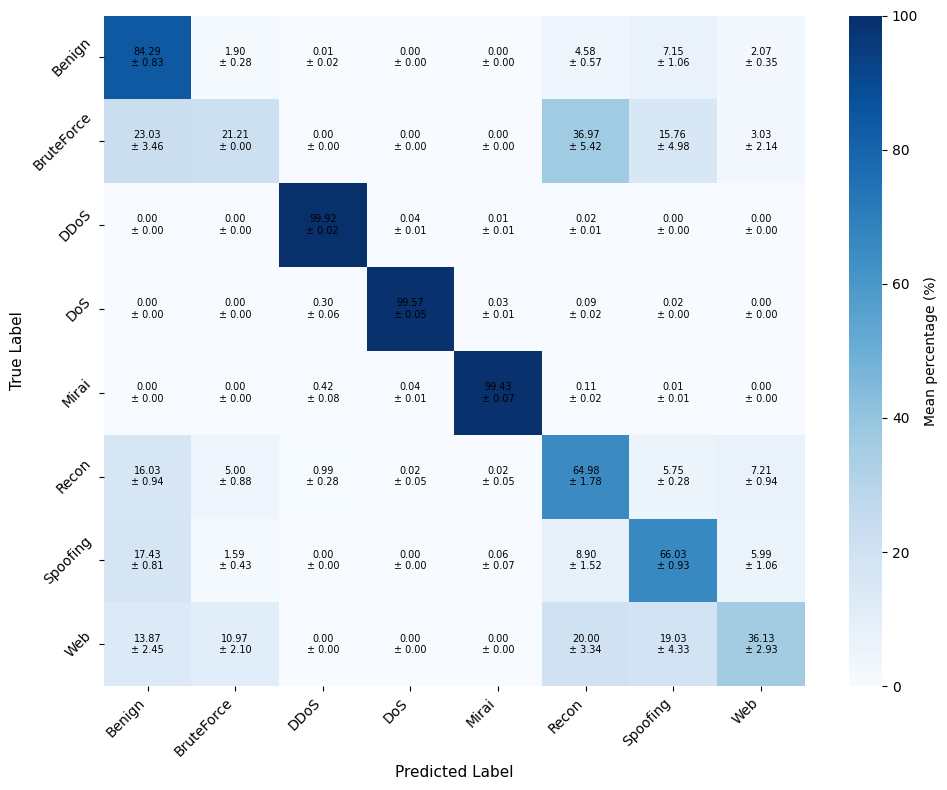

In [19]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# Compatible with the current LSTM notebook structure
# ============================================================

labels = np.arange(number_of_classes)
class_names = label_encoder.classes_

normalized_confusion_matrices = []


# ------------------------------------------------------------
# Build one normalized confusion matrix per seed
# ------------------------------------------------------------
for candidate in representative_candidates:

    seed_predictions = candidate["Predictions"]

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,
        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),
        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )


# Shape:
# (5, number_of_classes, number_of_classes)
normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)


# ------------------------------------------------------------
# Cell-wise mean and sample SD across the 5 seeds
# ------------------------------------------------------------
mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,   # sample SD across 5 independent seeds
)


# Convert to percentages
mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0


# ------------------------------------------------------------
# Create combined mean ± SD table
# ------------------------------------------------------------
mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(number_of_classes):
    for j in range(number_of_classes):

        mean_sd_table.iloc[i, j] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )


mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"


# Save combined table
mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.csv"
)


# ------------------------------------------------------------
# Save numerical mean and SD matrices separately
# ------------------------------------------------------------
pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
).to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean.csv"
)


pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
).to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_sd.csv"
)


# ------------------------------------------------------------
# Plot ONE mean ± SD confusion matrix
# ------------------------------------------------------------
plt.figure(
    figsize=(10, 8)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)


# Add mean ± SD text to each cell
for i in range(number_of_classes):
    for j in range(number_of_classes):

        ax.text(
            j + 0.5,
            i + 0.5,
            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),
            ha="center",
            va="center",
            fontsize=7,
        )


plt.xlabel(
    "Predicted Label",
    fontsize=11,
)

plt.ylabel(
    "True Label",
    fontsize=11,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=45,
)

plt.tight_layout()


plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

In [20]:
import shutil

# Compress the entire Kaggle working/output directory
shutil.make_archive(
    "/kaggle/working/Balanced_NoFA_CICIoT2023_LSTM_5Seed_V3",
    "zip",
    "/kaggle/working"
)

print("Created: /kaggle/working/Balanced_NoFA_CICIoT2023_LSTM_5Seed_V3.zip")

Created: /kaggle/working/Balanced_NoFA_CICIoT2023_LSTM_5Seed_V3.zip


## Offline inference timing with pretrained LSTM models


In [ ]:
# ============================================================
# Offline classifier inference timing using pretrained LSTM models
# ============================================================
# Reproduces classifier-only inference timing without retraining.
# Model loading and preprocessing are excluded from timed regions.
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

RESULT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

X_test_offline = np.load(
    RESULT_DIRECTORY / "X_test_model_input.npy"
)

RUN_SEEDS_OFFLINE = [42, 43, 44, 45, 46]
N_WARMUP_RUNS_OFFLINE = 3
N_TIMING_RUNS_OFFLINE = 5
N_TEST_SAMPLES = len(X_test_offline)

offline_timing_records = []

for run_index, seed in enumerate(
    RUN_SEEDS_OFFLINE,
    start=1,
):
    model_path = (
        RESULT_DIRECTORY
        / f"LSTM_Seed_{run_index}"
        / f"lstm_seed_{seed}.keras"
    )

    model = tf.keras.models.load_model(
        model_path,
        custom_objects={
            "SparseMacroF1": SparseMacroF1,
        },
    )

    for _ in range(N_WARMUP_RUNS_OFFLINE):
        _ = model.predict(
            X_test_offline,
            verbose=0,
        )

    for repetition in range(1, N_TIMING_RUNS_OFFLINE + 1):
        start_time = time.perf_counter()
        _ = model.predict(
            X_test_offline,
            verbose=0,
        )
        inference_time_s = time.perf_counter() - start_time

        offline_timing_records.append(
            {
                "Seed": seed,
                "Run": run_index,
                "Repetition": repetition,
                "Inference_Time_s": inference_time_s,
                "Latency_ms_per_sample": (
                    inference_time_s / N_TEST_SAMPLES * 1000.0
                ),
                "Throughput_samples_per_s": (
                    N_TEST_SAMPLES / inference_time_s
                ),
            }
        )

    del model
    tf.keras.backend.clear_session()

offline_timing_df = pd.DataFrame(
    offline_timing_records
)

offline_timing_df.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_repetitions.csv",
    index=False,
)

offline_seed_summary = (
    offline_timing_df
    .groupby("Seed", as_index=False)
    .agg(
        Mean_Inference_Time_s=("Inference_Time_s", "mean"),
        SD_Inference_Time_s=("Inference_Time_s", "std"),
        Mean_Latency_ms_per_sample=("Latency_ms_per_sample", "mean"),
        SD_Latency_ms_per_sample=("Latency_ms_per_sample", "std"),
        Mean_Throughput_samples_per_s=("Throughput_samples_per_s", "mean"),
    )
)

offline_seed_summary.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_per_seed.csv",
    index=False,
)

offline_final_summary = pd.DataFrame(
    {
        "Metric": [
            "Inference_Time_s",
            "Latency_ms_per_sample",
            "Throughput_samples_per_s",
        ],
        "Mean": [
            offline_seed_summary["Mean_Inference_Time_s"].mean(),
            offline_seed_summary["Mean_Latency_ms_per_sample"].mean(),
            offline_seed_summary["Mean_Throughput_samples_per_s"].mean(),
        ],
        "SD": [
            offline_seed_summary["Mean_Inference_Time_s"].std(ddof=1),
            offline_seed_summary["Mean_Latency_ms_per_sample"].std(ddof=1),
            offline_seed_summary["Mean_Throughput_samples_per_s"].std(ddof=1),
        ],
    }
)

offline_final_summary.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_summary.csv",
    index=False,
)

print("Offline LSTM inference timing completed.")
display(offline_seed_summary)
display(offline_final_summary)
